In [133]:
%pip install -q cleanco

import re
from math import comb

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cleanco import basename
from matplotlib.ticker import PercentFormatter
from scipy import stats
from sqlalchemy import func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN, TLS202_APPLN_TITLE, TLS203_APPLN_ABSTR,
    TLS206_PERSON, TLS207_PERS_APPLN, TLS224_APPLN_CPC,
)


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [134]:
ENV = "PROD"
NAME_METHOD = "dictionary"

SECTOR_NAME = "Surface drones (unmanned surface vessels)"
SECTOR_CPC_PREFIXES = (
    "B63B2035/006",   # unmanned surface vessels, e.g. remotely controlled
    "B63B2035/007",   # ... autonomously operating
    "B63B2035/008",   # ... remotely controlled
)
SECTOR_KEYWORDS = (
    "unmanned surface vessel", "unmanned surface vehicle",
    "autonomous surface vessel", "autonomous surface vehicle",
    "uncrewed surface", "surface drone", "drone boat",
    "unmanned boat", "autonomous boat", "unmanned ship", "autonomous ship",
    "unmanned vessel", "robotic boat",
)

YEAR_MIN, YEAR_MAX = 2000, 2025
LAST_COMPLETE_YEAR = YEAR_MAX - 3
IPR_TYPE = "PI"
SPLIT_YEAR = 2015
WINDOW = 3
TOP_N = 15

patstat = PatstatClient(env=ENV)
db = patstat.orm()


## Sector definition: families found by CPC codes and by keywords

In [135]:
def code_filter(column, codes):
    clean = func.replace(column, " ", "")
    return or_(*[clean.like(f"{c}%") for c in codes])

def keyword_filter(terms):
    title = func.lower(TLS202_APPLN_TITLE.appln_title)
    abstract = func.lower(TLS203_APPLN_ABSTR.appln_abstract)
    return or_(*[title.like(f"%{t}%") for t in terms], *[abstract.like(f"%{t}%") for t in terms])

family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")
q_cpc = (db.query(family_id)
         .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
         .filter(code_filter(TLS224_APPLN_CPC.cpc_class_symbol, SECTOR_CPC_PREFIXES)))
q_kw = (db.query(family_id)
        .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        .filter(keyword_filter(SECTOR_KEYWORDS)))

by_code = set(patstat.df(q_cpc)["docdb_family_id"])
by_kw = set(patstat.df(q_kw)["docdb_family_id"])
print("by codes:", len(by_code), "| by keywords:", len(by_kw), "| total:", len(by_code | by_kw))


by codes: 2436 | by keywords: 9025 | total: 10390


## Quality check of the sector

In [136]:
sector_families = by_code | by_kw

q_titles = (db.query(TLS201_APPLN.docdb_family_id, TLS202_APPLN_TITLE.appln_title)
            .join(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
            .filter(TLS201_APPLN.docdb_family_id.in_(list(sector_families))))
titles = patstat.df(q_titles).drop_duplicates("docdb_family_id").set_index("docdb_family_id")["appln_title"]

pd.set_option("display.max_colwidth", 120)
for label, ids in [("codes only", by_code - by_kw), ("keywords only", by_kw - by_code)]:
    print(f"\n=== {label}: 10 random titles ===")
    sample = titles[titles.index.isin(ids)].sample(10, random_state=1)
    for t in sample:
        print("-", t)



=== codes only: 10 random titles ===
- Identifying and remediating a gas leak
- WATER BODY MIXTURE MEASUREMENT BOAT AND WATER BODY MIXTURE MEASUREMENT METHOD
- AUTOMATED SURFACE RESCUE VEHICLE
- Fast disassembling and assembling semi-submersible three-body unmanned vehicle
- SURFACE PLATFORM, ESPECIALLY FOR TRACKING SUBMARINES
- ADCP water surface carrying device suitable for automatic flow measurement of cableway and flow measurement method of ADCP water surface carrying device
- VESSEL STEERING DEVICE AND INFORMATION PROCESSING SYSTEM
- Fishery detection device
- Unmanned marine surveying and mapping ship and use method
- AUTONOMOUS CONTROL SYSTEM AND METHOD FOR VESSEL

=== keywords only: 10 random titles ===
- Hanging basket for folding and unfolding unmanned ship
- Unmanned ship navigation system based on vision and biological monitoring
- Flexible unmanned ship collision-free following control method based on potential field prediction
- Unmanned ship with obstacle avoidance func

In [137]:
code_only = list(by_code - by_kw)

q_text = (db.query(TLS201_APPLN.docdb_family_id, TLS202_APPLN_TITLE.appln_title, TLS203_APPLN_ABSTR.appln_abstract)
          .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
          .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
          .filter(TLS201_APPLN.docdb_family_id.in_(code_only)))
text = patstat.df(q_text).fillna("")
text["text"] = (text["appln_title"] + " " + text["appln_abstract"]).str.lower()

# one long text per family (all its applications together)
family_text = text.groupby("docdb_family_id")["text"].apply(" ".join)

DRONE_WORDS = r"unmanned|uncrewed|autonom|drone|remote.?control|\busv\b|unattended|robot"
mentions = family_text.str.contains(DRONE_WORDS, regex=True)

kept, dropped = set(mentions[mentions].index), set(mentions[~mentions].index)
print("codes-only families:", len(code_only), "| kept:", len(kept), "| dropped:", len(dropped))

print("\n=== 10 dropped titles (check that they are really noise) ===")
for t in titles[titles.index.isin(dropped)].head(10):
    print("-", t)


codes-only families: 1365 | kept: 837 | dropped: 528

=== 10 dropped titles (check that they are really noise) ===
- WATER SKIING APPARATUS
- Water skiing unit, comprises a driver-less boat, a cable connected to it which contains control cables, and a hand grip with controls at the end of the cable for the skier
- Radio controlled water course flow rate probe has Doppler ultrasonic sensor on catamaran hull
- FIRE EXTINGUISHING SHIP
- SHIP CONTROL SYSTEM, CONTROL INPUT SYSTEM FOR SHIP, SHIP CONTROL DEVICE AND TRANSMITTER FOR SHIP CONTROL DEVICE
- A MODEL BOAT HAVING A FISHING BAIT DROPPER
- ACCESSORIES FOR FISHING
- DEVICE FOR THROWING A BAIT ON ENGIN BOAT
- REEL TYPE FISHING DEVICE FOR THROWING BAIT
- APPARATUS FOR PITCHING BAIT OF FISHING


### Final fix: two more drone words, and the final sector

In [138]:
DRONE_WORDS = (r"unmanned|uncrewed|crewless|pilotless|driver.?less|autonom|drone"
               r"|remote.?control|radio.?control|\busv\b|unattended|robot|payload|glider")
mentions = family_text.str.contains(DRONE_WORDS, regex=True)
kept = set(mentions[mentions].index)
print("codes-only kept:", len(kept), "of", len(code_only))

# FINAL SECTOR: keywords OR (codes AND drone words)
sector_families = by_kw | kept
print("final sector:", len(sector_families), "families")


codes-only kept: 860 of 1365
final sector: 9885 families


### Sector definition: frozen (PROD, 9,885 families)

**Rule:** keywords in title/abstract **OR** (CPC `B63B2035/006–008` **AND** drone words in title/abstract).

- Drone words extended after the PROD check of dropped titles ("radio controlled", "driver-less" boats were real USVs): `crewless`, `pilotless`, `driver.?less`, `radio.?control` added.
- Consumer RC / fishing-bait boats stay out of scope (dropped by the rule).
- **Underwater overlap:** 526 of 9,885 titles (5.3%) mention underwater/submarine/submersible/subsea; most are surface vessels that survey the seabed or launch/recover underwater robots → **kept**, no exclusion rule.
- **Flying drones:** 2 of 100 in a first title sample → no exclusion rule.
- Precision of the rule: measured on 100 random families below (`random_state=42`), labels in `work/validation/`.


In [139]:
final_titles = titles[titles.index.isin(sector_families)]
underwater = final_titles.str.contains(r"underwater|submarine|submersible|subsea", case=False)
print(f"{underwater.sum()} of {len(final_titles)} titles mention underwater ({underwater.mean():.1%})")
final_titles[underwater].sample(10, random_state=1)


526 of 9885 titles mention underwater (5.3%)


docdb_family_id
74782746      Unmanned underwater vehicle deploying and retrieving system and deploying and retrieving method
95974814                                       Unmanned ship for underwater topographic surveying and mapping
77802212                                                  Launch and recovery of underwater units or vehicles
87456310                     Method for automatically recovering and laying underwater robot by unmanned ship
66721215                  Water-cooling electronic speed controller system applied to underwater power device
98116066    Cross-domain collaborative underwater environment real-time observation system and method thereof
58995197                          UNMANNED SURFACE VESSEL FOR REMOTELY OPERATED UNDERWATER VEHICLE OPERATIONS
85649240                    Unmanned surface vehicle capable of cooperatively working with underwater vehicle
95034999              Underwater topographic survey method and system based on unmanned ship data acquis

In [140]:
validation = final_titles.sample(100, random_state=42).rename("title").to_frame()
validation["relevant (1/0)"] = ""
validation.to_csv("sector_validation_sample.csv")      # keeps the family ids (index)

## Applicants and CPC codes of the sector families

In [141]:
# 1. sector families with their year (= earliest priority year), real patents only
family_year = func.min(TLS201_APPLN.earliest_filing_year)
families = (
    db.query(TLS201_APPLN.docdb_family_id.label("unit_id"), family_year.label("year"))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE,
            TLS201_APPLN.appln_id < 900000000,                # drop PATSTAT's internal dummy rows
            TLS201_APPLN.docdb_family_id.in_(list(sector_families)))
    .group_by(TLS201_APPLN.docdb_family_id)
    .having(family_year.between(YEAR_MIN, YEAR_MAX))
    .subquery()
)

# 2. the applicants of every family: one row per (family, person)
q_sector = (
    db.query(families.c.unit_id, families.c.year,
             TLS206_PERSON.psn_id, TLS206_PERSON.psn_name, TLS206_PERSON.han_name,
             TLS206_PERSON.psn_sector, func.trim(TLS206_PERSON.person_ctry_code).label("ctry"))
    .select_from(families)
    .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == families.c.unit_id)
    .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
    .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0)          # applicants only, not inventors
    .distinct()
)
raw_sector = patstat.df(q_sector)

# 3. the CPC codes of every family (needed later for the subfields)
q_cpc_fam = (
    db.query(families.c.unit_id, families.c.year,
             func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "").label("cpc"))
    .select_from(families)
    .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == families.c.unit_id)
    .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    .distinct()
)
family_cpc = patstat.df(q_cpc_fam)

print(raw_sector["unit_id"].nunique(), "families with applicants |", len(raw_sector), "rows")
raw_sector.head()

7282 families with applicants | 9012 rows


,unit_id,year,psn_id,psn_name,han_name,psn_sector,ctry
0,97559800,2024,59601,4DREAM COMPANY,4DREAM CO LTD,COMPANY,KR
1,86573777,2022,62492,58TH RESEARCH INSTITUTE OF CETC,58TH RESEARCH INSTITUTE OF CETC,COMPANY,
2,72899607,2020,64420,"63983 FORCES, PLA","63983 FORCES, PLA",GOV NON-PROFIT,
3,97938510,2024,64420,"63983 FORCES, PLA","63983 FORCES, PLA",GOV NON-PROFIT,
4,82719288,2022,64420,"63983 FORCES, PLA","63983 FORCES, PLA",GOV NON-PROFIT,


## Raw applicant names: how many spellings?

In [142]:
print("different psn_name:", raw_sector["psn_name"].nunique())
print("different han_name:", raw_sector["han_name"].nunique())
print("different psn_id:  ", raw_sector["psn_id"].nunique())

(raw_sector.groupby("psn_name")["unit_id"].nunique()
           .sort_values(ascending=False).head(20))


different psn_name: 3054
different han_name: 3171
different psn_id:   3117


psn_name
DALIAN MARITIME UNIVERSITY                                                      427
HARBIN ENGINEERING UNIVERSITY                                                   276
SHANGHAI UNIVERSITY                                                             253
WUHAN UNIVERSITY OF TECHNOLOGY                                                  144
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY                                    141
SHANGHAI JIAO TONG UNIVERSITY                                                   111
SYSTEMS ENGINEERING RESEARCH INSTITUTE, CHINA STATE SHIPBUILDING CORPORATION     98
CSSC ZHIHAI INNOVATION RESEARCH INSTITUTE CO., LTD.                              93
CHINA SHIP DEVELOPMENT AND DESIGN CENTER                                         81
CHINESE ACADEMY OF SCIENCES                                                      71
HUAZHONG UNIVERSITY OF SCIENCE AND TECHNOLOGY                                    70
GUANGDONG OCEAN UNIVERSITY                                         

## Name cleaning: methods A (dictionary) and B (cleanco)

In [143]:
LEGAL_FORMS = {
    "INC", "INCORPORATED", "CORP", "CORPORATION", "CO", "COMPANY", "LTD", "LIMITED", "LLC", "LP", "PLC",
    "GMBH", "AG", "KG", "MBH", "SE", "SA", "SAS", "SPA", "SRL", "BV", "NV", "AB", "AS", "ASA", "OY", "OYJ",
    "KK", "KABUSHIKI", "KAISHA", "LTDA", "PTY", "THE", "AKTIENGESELLSCHAFT", "GESELLSCHAFT",
}

def clean_with_dictionary(name):
    "Method A: upper-case, keep letters/digits, drop legal-form words at the start and end."
    words = re.sub(r"[^A-Z0-9 ]", " ", str(name).upper()).split()
    while words and words[-1] in LEGAL_FORMS:
        words.pop()
    while words and words[0] in LEGAL_FORMS:
        words.pop(0)
    return " ".join(words)

def clean_with_cleanco(name):
    "Method B: cleanco removes legal forms first, then the same cleaning as A."
    return clean_with_dictionary(basename(str(name)))

# how many different names does each method leave?
names = raw_sector["psn_name"].drop_duplicates()
print("psn_name as is:", names.nunique())
print("method A:      ", names.map(clean_with_dictionary).nunique())
print("method B:      ", names.map(clean_with_cleanco).nunique())

# which names did method A merge?
merged = pd.DataFrame({"psn_name": names, "A": names.map(clean_with_dictionary)})
merged[merged.duplicated("A", keep=False)].sort_values("A")

psn_name as is: 3054
method A:       2964
method B:       2961


,psn_name,A
6991,オートノーマス マリーン システムズ インコーポレーテッドＡＵＴＯＮＯＭＯＵＳ ＭＡＲＩＮＥ ＳＹＳＴＥＭＳ， ＩＮＣ．,
6994,波音公司,
6995,福特全球技术公司,
6996,自动化机器人公司,
8822,株式会社Ｏｃｅａｎｉｃ Ｃｏｎｓｔｅｌｌａｔｉｏｎｓ,
...,...,...
6910,ZHUHAI YUNZHOU INTELLIGENCE TECHNOLOGY,ZHUHAI YUNZHOU INTELLIGENCE TECHNOLOGY
8007,"ZHUHAI YUNZHOU INTELLIGENCE TECHNOLOGY CO., LTD.",ZHUHAI YUNZHOU INTELLIGENCE TECHNOLOGY
7814,ZHUHAI YUNZHOU INTELLIGENCE TECHNOLOGY LTD,ZHUHAI YUNZHOU INTELLIGENCE TECHNOLOGY
7088,Zhukov Aleksandr Vladimirovich,ZHUKOV ALEKSANDR VLADIMIROVICH


In [144]:

GOLD_STANDARD_FILE = "https://raw.githubusercontent.com/goksuyegen/innovation-management-datascience26/main/tutorial_1/PATSTAT_500_label_datav4.csv"
gold = pd.read_csv(GOLD_STANDARD_FILE).rename(columns={"comp": "name", "Group": "gold_group"})
print(f"{len(gold):,} names in {gold['gold_group'].nunique():,} organisations")


def pairs_inside(group_sizes):
    "Number of pairs inside groups of these sizes: n(n-1)/2 each."
    return sum(comb(int(n), 2) for n in group_sizes)


def precision_recall_f1(gold_groups, predicted_groups):
    df = pd.DataFrame({"gold": list(gold_groups), "pred": list(predicted_groups)})
    tp = pairs_inside(df.groupby(["gold", "pred"]).size())   # pairs we merged AND that are truly the same
    tp_fp = pairs_inside(df.groupby("pred").size())          # all pairs we merged
    tp_fn = pairs_inside(df.groupby("gold").size())          # all pairs that truly belong together
    precision = tp / tp_fp if tp_fp else 1.0
    recall = tp / tp_fn
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"groups found": df["pred"].nunique(), "precision": precision, "recall": recall, "F1": f1}


methods = {
    "no cleaning": lambda n: n,
    "A dictionary": clean_with_dictionary,
    "B cleanco": clean_with_cleanco,
}
pd.DataFrame({label: precision_recall_f1(gold["gold_group"], gold["name"].map(f))
              for label, f in methods.items()}).T.round(3)


3,192 names in 481 organisations


,groups found,precision,recall,F1
no cleaning,3192.0,1.000,0.000,0.000
A dictionary,3010.0,0.995,0.002,0.004
B cleanco,2984.0,0.996,0.003,0.005


In [145]:
def method_c(name):
    "Method C: the first word of the cleaned name."
    words = clean_with_dictionary(name).split()
    return words[0] if words else ""

methods["C first word"] = method_c
pd.DataFrame({label: precision_recall_f1(gold["gold_group"], gold["name"].map(f))
              for label, f in methods.items()}).T.round(3)


,groups found,precision,recall,F1
no cleaning,3192.0,1.000,0.000,0.000
A dictionary,3010.0,0.995,0.002,0.004
B cleanco,2984.0,0.996,0.003,0.005
C first word,536.0,0.961,0.923,0.942


In [146]:
check = pd.DataFrame({
    "psn_name": names,
    "A": names.map(clean_with_dictionary),
    "C": names.map(method_c),
})
over_merged = check.groupby("C").filter(lambda g: g["A"].nunique() > 1)
print("names merged by C but not by A:", len(over_merged))
over_merged.sort_values("C")


names merged by C but not by A: 2078


,psn_name,A,C
5891,THE 715TH RESEARCH INSTITUTE OF CHINA SHIPBUILDING INDUSTRY CORPORATION,715TH RESEARCH INSTITUTE OF CHINA SHIPBUILDING INDUSTRY,715TH
8114,THE 715TH RESEARCH INSTITUTE OF CHINA STATE SHIPBUILDING CORPORATION LIMITED,715TH RESEARCH INSTITUTE OF CHINA STATE SHIPBUILDING,715TH
7404,716TH RESEARCH INSTITUTE OF CHINA STATE SHIPBUILDING CORPORATION LIMITED,716TH RESEARCH INSTITUTE OF CHINA STATE SHIPBUILDING,716TH
8,716TH RESEARCH INSTITUTE OF CHINA SHIPBUILDING INDUSTRY CORPORATION,716TH RESEARCH INSTITUTE OF CHINA SHIPBUILDING INDUSTRY,716TH
8151,"724TH RESEARCH INSTITUTE, CHINA SHIPBUILDING GROUP CO., LTD.",724TH RESEARCH INSTITUTE CHINA SHIPBUILDING GROUP,724TH
...,...,...,...
6900,ZHUHAI LANCHUANG TECHNOLOGY COMPANY,ZHUHAI LANCHUANG TECHNOLOGY,ZHUHAI
6910,ZHUHAI YUNZHOU INTELLIGENCE TECHNOLOGY,ZHUHAI YUNZHOU INTELLIGENCE TECHNOLOGY,ZHUHAI
6904,ZHUHAI YUNKUN TECHNOLOGY COMPANY,ZHUHAI YUNKUN TECHNOLOGY,ZHUHAI
8007,"ZHUHAI YUNZHOU INTELLIGENCE TECHNOLOGY CO., LTD.",ZHUHAI YUNZHOU INTELLIGENCE TECHNOLOGY,ZHUHAI


## Applicant table: cleaned name (method A) and type

Method C scored best on the gold standard (F1 = 0.94) but on our sector it merges 67 names of unrelated organisations (e.g. all "ZHEJIANG …" universities and firms), because Chinese names start with a city. **We use method A.**
Research institutes and subsidiaries are merged into their group (ultimate owner)

In [147]:
NAME_MERGES = {                        # checked by hand: cleaned name -> group name
    "GUANGZHOU SHUNHAI SHIP MAKING": "GUANGZHOU SHUNHAI SHIPYARDS",
    # CSIC research institutes -> one group (your decision!)
    "CHINA SHIPBUILDING INDUSTRY CORPORATION NO 707 RESEARCH INSTITUTE": "CHINA SHIPBUILDING INDUSTRY CORPORATION (CSIC)",
    "715TH RESEARCH INSTITUTE OF CHINA SHIPBUILDING INDUSTRY": "CHINA SHIPBUILDING INDUSTRY CORPORATION (CSIC)",
}



In [148]:
def applicant_type(psn_sector):
    "Turn PATSTAT's psn_sector into a few simple types."
    s = str(psn_sector).upper()
    if "UNIVERSITY" in s:
        return "university"
    if "COMPANY" in s:
        return "firm"
    if "GOV" in s:
        return "government / non-profit"
    if "INDIVIDUAL" in s:
        return "individual"
    return "unknown"

links = raw_sector.copy()
links["applicant"] = links["psn_name"].map(clean_with_dictionary).replace(NAME_MERGES)
links["type"] = links["psn_sector"].map(applicant_type)

print(links["type"].value_counts())
links.groupby("applicant")["unit_id"].nunique().sort_values(ascending=False).head(20)


type
university                 3614
unknown                    2141
firm                       2139
government / non-profit     561
individual                  557
Name: count, dtype: int64


applicant
DALIAN MARITIME UNIVERSITY                                         427
HARBIN ENGINEERING UNIVERSITY                                      276
SHANGHAI UNIVERSITY                                                253
WUHAN UNIVERSITY OF TECHNOLOGY                                     144
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY                       141
SHANGHAI JIAO TONG UNIVERSITY                                      111
SYSTEMS ENGINEERING RESEARCH INSTITUTE CHINA STATE SHIPBUILDING     98
CSSC ZHIHAI INNOVATION RESEARCH INSTITUTE                           93
ZHUHAI YUNZHOU INTELLIGENCE TECHNOLOGY                              88
CHINA SHIP DEVELOPMENT AND DESIGN CENTER                            81
CHINESE ACADEMY OF SCIENCES                                         71
HUAZHONG UNIVERSITY OF SCIENCE AND TECHNOLOGY                       70
GUANGDONG OCEAN UNIVERSITY                                          67
ZHEJIANG UNIVERSITY                                                

In [149]:
display(links.drop_duplicates("applicant")["type"].value_counts())
links.loc[links["type"] == "unknown", "psn_name"].unique()

type
unknown                    1003
firm                        969
university                  414
individual                  395
government / non-profit     181
Name: count, dtype: int64

array(['AHARON HANOCH', 'AL MARAKEB MANUFACTURING BOATS EST',
       'ALGORITHME', ..., 'Pattabhi Madhumati',
       'JILIN SHUITOU INVESTMENT CONSTRUCTION CO., LTD.',
       'JINGJIANG YUHAO FASTENER MANUFACTURING CO., LTD.'],
      shape=(1114,), dtype=object)

In [150]:
FIRM_WORDS = {"CO", "LTD", "LIMITED", "INC", "COMPANY", "CORP", "LLC", "GMBH", "SRL"}

def type_from_name(name):
    "Guess the type from the words of the name (used only when psn_sector says nothing)."
    words = set(re.sub(r"[^A-Z0-9 ]", " ", str(name).upper()).split())
    if words & FIRM_WORDS:
        return "firm"
    if words & {"UNIVERSITY", "COLLEGE"}:
        return "university"
    if words & {"INSTITUTE", "ACADEMY"}:
        return "government / non-profit"
    return "unknown"

unknown = links["type"] == "unknown"
links.loc[unknown, "type"] = links.loc[unknown, "psn_name"].map(type_from_name)

TYPE_FIXES = {                       # checked by hand
    "XUNORD S R L": "firm",
    "ETME PEPPAS KAI SYNERGATES E E": "firm",
}
links["type"] = links["applicant"].map(TYPE_FIXES).fillna(links["type"])

links.loc[links["type"] == "unknown", "psn_name"].unique()   # what is still unknown?

array(['AHARON HANOCH', 'AL MARAKEB MANUFACTURING BOATS EST',
       'ALGORITHME', 'BENEDICT SARAH', 'BENNETT MATTHEW', 'BROOK, NOAM',
       'CANKAYA UNİVERSİTESİ', 'CAO JINBO', 'CARDOZA MIGUEL A.',
       'CHANGJIANG LUZHOU WATERWAY BUREAU',
       'CHANGJIANG YICHANG WATERWAY ENGINEERING BUREAU', 'CHENG QILIANG',
       'CHINA INDUSTRIAL CONTROL SYSTEMS CYBER EMERGENCY RESPONSE TEAM',
       'CHO, SEUNG WOO', 'CIULKIEWICZ JEAN LUC', 'DAUM ENGINEERING',
       'DEC N.V. (DEME ENVIRONMENTAL CONTRACTORS)',
       'DOKUZ EYLUL UNİVERSİTESİ REKTORLUĞU', 'DU MINGFANG', 'DUAN LINNA',
       'E-4S', 'ECA',
       'ETAT FRANCAIS REPRESENTE PAR LE DELEGUE GENERAL PO',
       'FOSHAN CHANCHENG ENVIRONMENTAL MONITORING STATION',
       'GENERAL HOSPITAL OF NORTHERN THEATER COMMAND OF PLA',
       'GIBBS, SIMON',
       'GUANGDONG LABORATORY OF SOUTHERN OCEAN SCIENCE AND ENGINEERING (ZHANJIANG)',
       'GUANGDONG PROVINCIAL LABORATORY OF SOUTHERN MARINE SCIENCE AND ENGINEERING (GUANGZHOU)',
   

## Country of each applicant

In [151]:
links["ctry"] = links["ctry"].replace("", np.nan)

per_applicant = links.groupby("applicant")["ctry"].apply(lambda c: c.notna().any())
print("applicants with no country at all:", (~per_applicant).sum(), "of", len(per_applicant))

applicants with no country at all: 2015 of 2962


Get the office of each family 

In [152]:
q_offices = (db.query(families.c.unit_id, TLS201_APPLN.appln_auth)
             .select_from(families)
             .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == families.c.unit_id)
             .distinct())
family_offices = patstat.df(q_offices)
family_offices["appln_auth"].value_counts().head(10)


appln_auth
CN    6398
KR     527
US     317
WO     311
EP     121
JP      70
AU      60
CA      34
GB      34
ES      27
Name: count, dtype: int64

one country per applicant 4b

In [153]:
def most_frequent(values):
    return values.value_counts().index[0]

# 1. the country written on the patents (most frequent one)
known = links.dropna(subset=["ctry"]).drop_duplicates(["unit_id", "applicant", "ctry"])
main_country = known.groupby("applicant")["ctry"].agg(most_frequent)

# 2. fallback: the most frequent national office of its families
national = family_offices[~family_offices["appln_auth"].isin(["EP", "WO"])]
offices = links[["unit_id", "applicant"]].drop_duplicates().merge(national, on="unit_id")
main_office = offices.groupby("applicant")["appln_auth"].agg(most_frequent)

# 3. combine: written country first, office if there is none
links["country"] = links["applicant"].map(main_country).fillna(links["applicant"].map(main_office))
links["country_source"] = np.where(links["applicant"].isin(main_country.index), "written",
                          np.where(links["country"].notna(), "office", "missing"))

# 4. hand fixes (checked by hand)
COUNTRY_FIXES = {"PEPPAS ANTONIOS": "GR"}
fix = links["applicant"].isin(COUNTRY_FIXES)
links.loc[fix, "country"] = links.loc[fix, "applicant"].map(COUNTRY_FIXES)
links.loc[fix, "country_source"] = "hand"

# one row per applicant, AFTER all the fixes
per_app = links.drop_duplicates("applicant")
display(per_app["country_source"].value_counts())
per_app["country"].value_counts().head(10)

country_source
office     2014
written     947
hand          1
Name: count, dtype: int64

country
CN    2078
KR     297
US     254
JP      50
GB      35
DE      28
ES      20
IL      19
FR      18
NO      16
Name: count, dtype: int64

In [154]:
pd.crosstab(per_app["country"], per_app["country_source"])


country_source,hand,office,written
country,,,
AE,0,0,1
AR,0,0,3
AT,0,0,4
AU,0,2,6
BA,0,0,1
BE,0,0,2
BG,0,0,2
CA,0,0,14
CH,0,0,3


In [155]:
per_app.loc[(per_app["country_source"] == "office") & (per_app["country"] != "CN"), ["applicant", "country"]]


,applicant,country
17,A P,SG
28,AERO ASAHI,JP
177,ASANUMA,JP
909,CHO SHOICHIRO,JP
1592,DONGGUAN YIDONG INTELLIGENT TECHNOLOGY,US
1604,EAMS LAB,JP
1605,EAMS ROBOTICS,JP
2227,HANSHIN EXPRESSWAY ENGINEERING,JP
2943,IHI ISHIKAWAJIMA HARIMA HEAVY INDUSTRIES,JP
2993,IZU TOMOYUKI,JP


In [156]:
for word in ["SHUNHAI", "SHIPBUILDING", "PEPPAS"]:
    print(word, "->", sorted(links.loc[links["applicant"].str.contains(word), "applicant"].unique()))


SHUNHAI -> ['GUANGZHOU SHUNHAI SHIPYARDS']
SHIPBUILDING -> ['715TH RESEARCH INSTITUTE OF CHINA STATE SHIPBUILDING', '716TH RESEARCH INSTITUTE OF CHINA SHIPBUILDING INDUSTRY', '716TH RESEARCH INSTITUTE OF CHINA STATE SHIPBUILDING', '719TH RESEARCH INSTITUTE OF CHINA SHIPBUILDING INDUSTRY', '724TH RESEARCH INSTITUTE CHINA SHIPBUILDING GROUP', '724TH RESEARCH INSTITUTE CHINA SHIPBUILDING INDUSTRY', '724TH RESEARCH INSTITUTE OF CHINA STATE SHIPBUILDING', 'CENTRAL CHINA INSTITUTE OF OPTOELECTRONIC TECHNOLOGY CHINA SHIPBUILDING INDUSTRY CORPORATION NO 717 RESEARCH INSTITUTE', 'CENTRAL CHINA OPTOELECTRONIC TECHNOLOGY RESEARCH INSTITUTE CHINA SHIPBUILDING INDUSTRY CORPORATION LIMITED 77TH RESEARCH INSTITUTE', 'CHINA SHIP RESEARCH AND DEVELOPMENT ACADEMY NO 7 RESEARCH INSTITUTE OF CHINA SHIPBUILDING GROUP', 'CHINA SHIP RESEARCH AND DEVELOPMENT ACADEMY NO 7 RESEARCH INSTITUTE OF CHINA SHIPBUILDING INDUSTRY', 'CHINA SHIPBUILDING GROUP FENXI HEAVY INDUSTRY', 'CHINA SHIPBUILDING INDUSTRY CORPORATIO

## Q1: Concentration

In [157]:
# one row per (family, applicant)
links = links.drop_duplicates(["unit_id", "applicant"])

# Q1 input: families per applicant, complete years only
complete = links[links["year"] <= LAST_COMPLETE_YEAR]
families_per_applicant = complete.groupby("applicant")["unit_id"].nunique()

print(len(families_per_applicant), "applicants,", families_per_applicant.sum(), "applicant-family pairs")
families_per_applicant.value_counts().sort_index()


1979 applicants, 4787 applicant-family pairs


unit_id
1      1467
2       250
3        78
4        54
5        26
6        16
7        11
8         6
9         9
10        5
11        6
12        3
13        3
14        4
15        3
16        2
17        3
18        3
19        1
20        1
21        1
24        2
25        2
26        1
27        2
29        2
30        4
31        1
34        1
36        1
40        1
41        1
47        1
49        1
52        1
70        1
76        1
91        1
170       1
171       1
185       1
Name: count, dtype: int64

In [158]:
def concentration_ratio(counts, k):
    "Share (%) of all families held by the k largest applicants."
    largest_first = np.sort(counts)[::-1]
    return largest_first[:k].sum() / largest_first.sum() * 100

def herfindahl(counts):
    "Sum of the squared shares: 1 = monopoly, 1/N = N equal players."
    shares = np.asarray(counts) / np.sum(counts)
    return np.sum(shares ** 2)

counts = families_per_applicant.to_numpy()
hhi = herfindahl(counts)
print(f"CR4   = {concentration_ratio(counts, 4):.1f}%")
print(f"CR8   = {concentration_ratio(counts, 8):.1f}%")
print(f"HHI   = {hhi:.4f}")
print(f"1/HHI = {1 / hhi:.0f} equivalent players (out of {len(counts)} real ones)")


CR4   = 12.9%
CR8   = 18.0%
HHI   = 0.0065
1/HHI = 154 equivalent players (out of 1979 real ones)


In [159]:
def concentration(rows):
    "CR4, HHI and 1/HHI for a set of (family, applicant) rows."
    counts = rows.groupby("applicant")["unit_id"].nunique().to_numpy()
    hhi = herfindahl(counts)
    return {"families": rows["unit_id"].nunique(),
            "applicants": len(counts),
            "CR4 (%)": concentration_ratio(counts, 4),
            "HHI": hhi,
            "1/HHI": 1 / hhi}

organisations = complete[complete["type"] != "individual"]
pd.DataFrame({"all applicants": concentration(complete),
              "without individuals": concentration(organisations)}).round(3)


,all applicants,without individuals
families,4008.000,3812.000
applicants,1979.000,1612.000
CR4 (%),12.889,14.207
HHI,0.007,0.008
1/HHI,153.550,127.613


In [160]:
rows = []
for end in range(LAST_COMPLETE_YEAR, YEAR_MIN + WINDOW - 2, -WINDOW):
    start = end - WINDOW + 1
    window = organisations[organisations["year"].between(start, end)]
    if window.empty:
        continue
    rows.append({"window": f"{start}-{end}", **concentration(window)})

over_time = pd.DataFrame(rows).set_index("window").sort_index()
over_time.round(3)


,families,applicants,CR4 (%),HHI,1/HHI
window,,,,,
2002-2004,15,22,28.000,0.059,16.892
2005-2007,17,17,36.364,0.066,15.125
2008-2010,26,28,27.273,0.051,19.800
2011-2013,82,68,21.782,0.027,36.827
2014-2016,247,170,15.412,0.013,76.994
2017-2019,1393,572,19.048,0.014,70.853
2020-2022,2024,977,11.972,0.007,142.496


## Summary of the results so far (keep this cell at the end)

In [161]:
per_app = links.drop_duplicates("applicant")

print(f"ENV: {ENV}  |  sector: {SECTOR_NAME}")
print(f"\nSector families: {len(sector_families)} (codes {len(by_code)}, keywords {len(by_kw)}, codes kept after drone words {len(kept)})")
print(f"Families with applicants ({YEAR_MIN}-{YEAR_MAX}, {IPR_TYPE}): {raw_sector['unit_id'].nunique()}")
print(f"Names: psn_name {raw_sector['psn_name'].nunique()} -> applicants after method A + hand merges {links['applicant'].nunique()}")
print(f"Country: {(per_app['country_source'] == 'written').sum()} written, "
      f"{(per_app['country_source'] == 'office').sum()} from office, "
      f"{(per_app['country_source'] == 'hand').sum()} by hand, "
      f"{per_app['country'].isna().sum()} missing")

print("\nApplicants by type:")
print(per_app["type"].value_counts().to_string())

print("\nTop 10 applicants (families):")
print(links.groupby("applicant")["unit_id"].nunique().sort_values(ascending=False).head(10).to_string())

print("\nApplicants by country (top 5):")
print(per_app["country"].value_counts().head(5).to_string())

ENV: PROD  |  sector: Surface drones (unmanned surface vessels)

Sector families: 9885 (codes 2436, keywords 9025, codes kept after drone words 860)
Families with applicants (2000-2025, PI): 7282
Names: psn_name 3054 -> applicants after method A + hand merges 2962
Country: 947 written, 2014 from office, 1 by hand, 0 missing

Applicants by type:
type
firm                       1542
university                  505
individual                  395
unknown                     270
government / non-profit     250

Top 10 applicants (families):
applicant
DALIAN MARITIME UNIVERSITY                                         427
HARBIN ENGINEERING UNIVERSITY                                      276
SHANGHAI UNIVERSITY                                                253
WUHAN UNIVERSITY OF TECHNOLOGY                                     144
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY                       141
SHANGHAI JIAO TONG UNIVERSITY                                      111
SYSTEMS ENGINEERING R

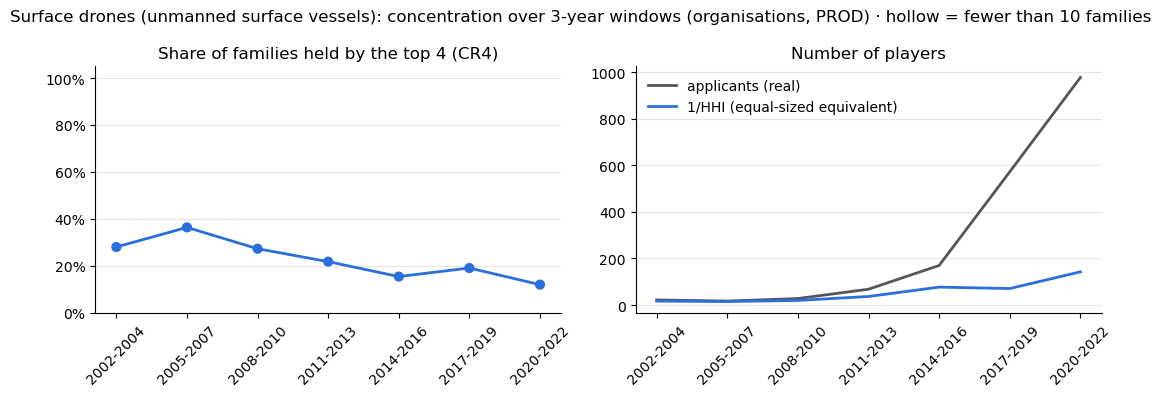

In [162]:
MIN_FAMILIES = 10                      # windows with fewer families are too small to read
reliable = (over_time["families"] >= MIN_FAMILIES).to_numpy()
x = np.arange(len(over_time))
ACCENT, NEUTRAL = "#2a6fdb", "#555555"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# left: CR4
ax1.plot(x, over_time["CR4 (%)"], color=ACCENT, lw=2)
ax1.scatter(x, over_time["CR4 (%)"], s=40, zorder=3,
            color=np.where(reliable, ACCENT, "white"), edgecolor=ACCENT)
ax1.set(title="Share of families held by the top 4 (CR4)", ylim=(0, 105))
ax1.yaxis.set_major_formatter(PercentFormatter(100))

# right: real players vs equal-sized equivalent (same unit: number of players)
ax2.plot(x, over_time["applicants"], color=NEUTRAL, lw=2, label="applicants (real)")
ax2.plot(x, over_time["1/HHI"], color=ACCENT, lw=2, label="1/HHI (equal-sized equivalent)")
ax2.set(title="Number of players")
ax2.legend(frameon=False)

for ax in (ax1, ax2):
    ax.set_xticks(x, over_time.index, rotation=45)
    ax.grid(axis="y", color="#e5e5e5")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"{SECTOR_NAME}: concentration over {WINDOW}-year windows "
             f"(organisations, {ENV}) · hollow = fewer than {MIN_FAMILIES} families")
plt.tight_layout()
plt.show()
